<div style="background:linear-gradient(90deg,#1e3a8a,#0ea5e9);padding:22px 26px;border-radius:12px;color:white">
<h1 style="color:white;margin:0">📡 Who Cancels? Predicting Customer Churn at a Telecom Company</h1>
<p style="margin:6px 0 0 0;font-size:15px">INFO 4604 · Portfolio Project · Nikhil Pudtha</p>
</div>

## 1. The Dataset and Why I Picked It

For this project I went with the **IBM Telco Customer Churn** dataset. It has **7,043 customers** from a phone and internet provider. Each row is one customer: what kind of contract they're on, how they pay, what their monthly bill is, which services they use (internet, streaming, tech support) and a **`Churn`** column that says whether they cancelled in the last month.

**Why I picked it:** I work as a student analyst at the CU Boulder IT Service Center, and a lot of what I deal with is networking and internet problems. I talk to frustrated people all the time, and I've noticed that how a support experience goes can make or break how someone feels about a service. That made me curious about the other side of it: from the provider's point of view, can you actually tell who's about to give up and leave?

It also matters a lot to the business. Keeping a customer is way cheaper than finding a new one, so churn prediction shows up everywhere in telecom, tech and subscription companies. I'm a CS major with a data science minor, and this felt like a project where the ML actually connects to a real decision someone would make, like reaching out with a better deal or a support call before a customer walks.

<div style="border-left:6px solid #2563eb;background:#eff6ff;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#2563eb">Goal</b><br>Predict <b>Churn (Yes/No)</b> from account and service data, and learn which factors push customers away.</div>

Source: IBM sample data, <a href="https://github.com/IBM/telco-customer-churn-on-icp4d">github.com/IBM/telco-customer-churn-on-icp4d</a>

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

# load the data
df = pd.read_csv("data/telco_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Feature Engineering

### 2a. Class (im)balance

Churn
No     5174
Yes    1869
Name: count, dtype: int64 

Churn
No     73.5%
Yes    26.5%
Name: count, dtype: str


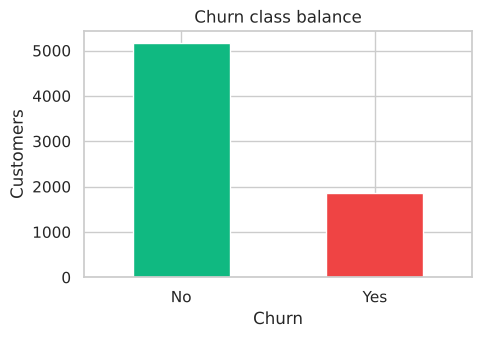

In [2]:
# how many left vs stayed
counts = df["Churn"].value_counts()
print(counts, "\n")
print((counts / len(df) * 100).round(1).astype(str) + "%")

ax = counts.plot(kind="bar", color=["#10b981", "#ef4444"], figsize=(5, 3.2), rot=0)
ax.set_title("Churn class balance")
ax.set_ylabel("Customers")
plt.show()

<div style="border-left:6px solid #d97706;background:#fffbeb;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d97706">What I see</b><br>About <b>73% stayed and 27% left</b>. So it's imbalanced, and a lazy model that just says "No" every time would already get 73% accuracy. That's why later I use <code>class_weight='balanced'</code> and care more about how many churners I actually catch (recall) than raw accuracy.</div>

### 2b. Feature histograms and outliers

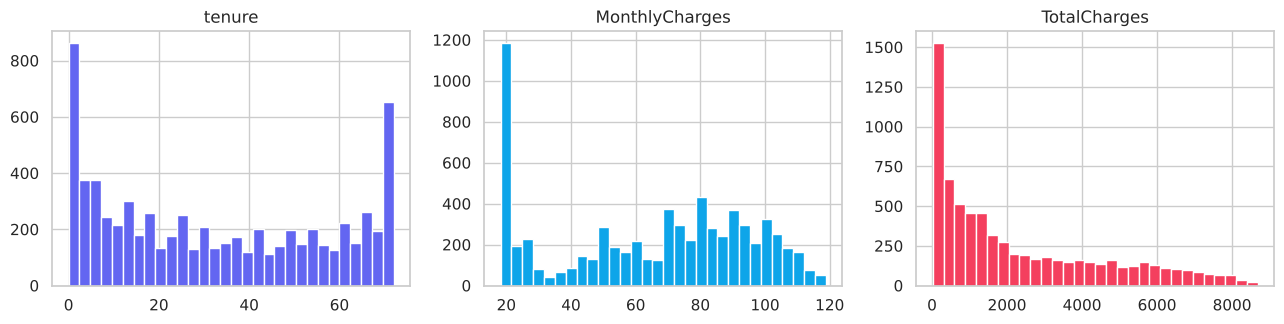

tenure          outliers by IQR rule: 0
MonthlyCharges  outliers by IQR rule: 0
TotalCharges    outliers by IQR rule: 0


In [3]:
# TotalCharges loads as text (blank cells), convert to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, c in zip(axes, num_cols, ["#6366f1", "#0ea5e9", "#f43f5e"]):
    ax.hist(df[col].dropna(), bins=30, color=c, edgecolor="white")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# count outliers with the IQR rule
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:15s} outliers by IQR rule: {n_out}")

<div style="border-left:6px solid #059669;background:#ecfdf5;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#059669">What I see</b><br>The IQR check found <b>zero outliers</b>, so I didn't remove anything. The shapes are still interesting though. <b>tenure</b> spikes at 1 month and at 72 months, so there are tons of brand new customers and tons of really loyal ones. <b>MonthlyCharges</b> has a big bump around $20, which I'm guessing is the phone only plans. <b>TotalCharges</b> is skewed right, which makes sense since it just keeps adding up the longer you stay.</div>

### 2c. Impute missing values

In [4]:
# missing values
print(df.isna().sum()[df.isna().sum() > 0])

print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head())

TotalCharges    11
dtype: int64
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN


In [5]:
# all tenure 0 (never billed yet), so fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


### 2d. Encode text fields

In [6]:
# drop ID
df = df.drop(columns="customerID")

# Yes/No to 1/0
binary = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
for col in binary:
    df[col] = df[col].map({"Yes": 1, "No": 0})
df["gender"] = df["gender"].map({"Male": 1, "Female": 0})

# contract has an order, so ordinal
df["Contract"] = df["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})

# no order, so one hot
nominal = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
           "TechSupport", "StreamingTV", "StreamingMovies", "PaymentMethod"]
df = pd.get_dummies(df, columns=nominal, drop_first=True, dtype=int)
print(df.shape)
df.head(3)

(7043, 30)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,...,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,1,29.85,29.85,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,1,0,56.95,1889.50,...,1,0,0,0,0,0,0,0,0,1
2,1,0,0,0,2,1,0,1,53.85,108.15,...,0,0,0,0,0,0,0,0,0,1


### 2e. Check for correlated columns

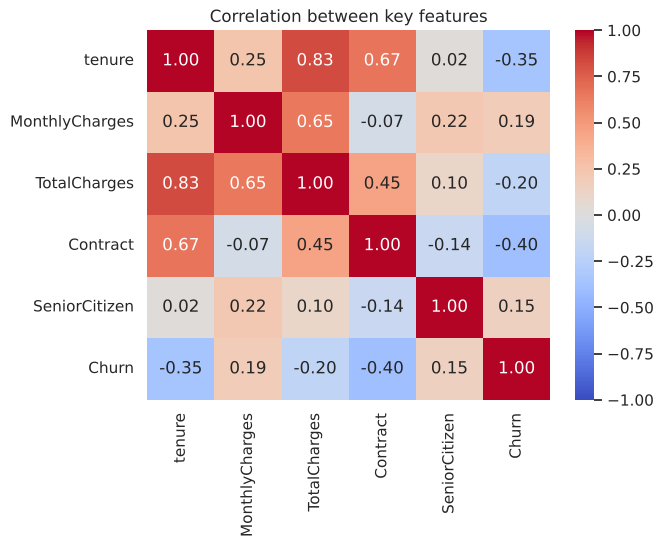

23 strongly correlated pairs, for example:
OnlineBackup_No internet service      StreamingMovies_No internet service     1.0
                                      StreamingTV_No internet service         1.0
DeviceProtection_No internet service  StreamingTV_No internet service         1.0
                                      TechSupport_No internet service         1.0
InternetService_No                    DeviceProtection_No internet service    1.0
DeviceProtection_No internet service  StreamingMovies_No internet service     1.0
TechSupport_No internet service       StreamingMovies_No internet service     1.0
PhoneService                          MultipleLines_No phone service          1.0
dtype: float64


In [7]:
# correlation heatmap
key = ["tenure", "MonthlyCharges", "TotalCharges", "Contract", "SeniorCitizen", "Churn"]
plt.figure(figsize=(6.5, 4.8))
sns.heatmap(df[key].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between key features")
plt.show()

# check all pairs for |r| > 0.8
def strong_pairs(frame, thresh=0.8):
    corr = frame.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().sort_values(ascending=False)
    return pairs[pairs > thresh]

pairs = strong_pairs(df.drop(columns="Churn"))
print(len(pairs), "strongly correlated pairs, for example:")
print(pairs.head(8))

In [8]:
# drop duplicate dummy columns
redundant = [c for c in df.columns if c.endswith("_No internet service")] + ["MultipleLines_No phone service"]

# and TotalCharges (~ tenure x MonthlyCharges)
df = df.drop(columns=redundant + ["TotalCharges"])

print("Columns now:", df.shape[1])
print(strong_pairs(df.drop(columns="Churn"), 0.75))

Columns now: 22
MonthlyCharges  InternetService_Fiber optic    0.787066
                InternetService_No             0.763557
dtype: float64


<div style="border-left:6px solid #7c3aed;background:#f5f3ff;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#7c3aed">What I see</b><br><b>tenure and TotalCharges are about 0.83 correlated</b>, so I dropped TotalCharges. I also didn't expect one hot encoding to create <b>7 duplicate columns</b> (every "No internet service" flag is the exact same as InternetService_No), so those went too. In the Churn row, <b>Contract (−0.40) and tenure (−0.35)</b> stand out the most. Basically, the more someone is locked in, the less likely they are to leave. Higher monthly bills go along with a bit more churn (+0.19).</div>

## 3. Looking for Clusters (without using y)

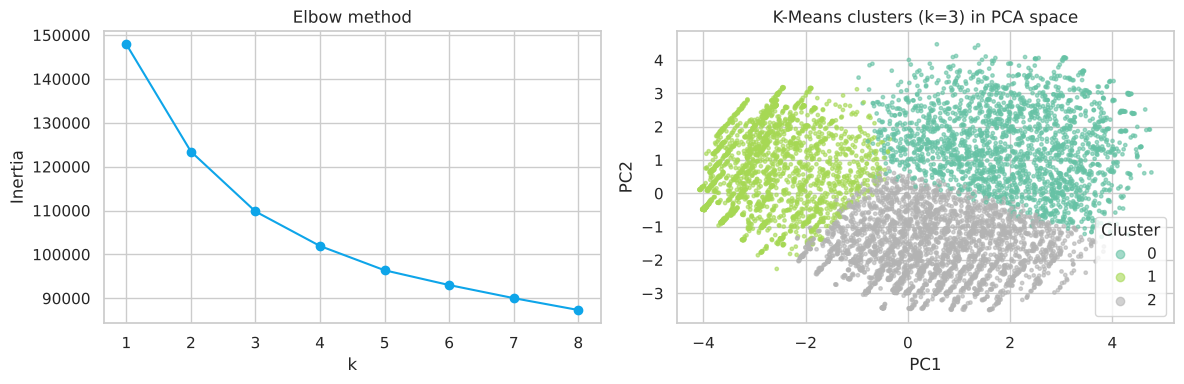

In [9]:
# cluster without Churn
X_all = df.drop(columns="Churn")
X_scaled = StandardScaler().fit_transform(X_all)

# elbow method
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_ for k in range(1, 9)]

# k = 3, PCA to 2D to plot
km = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = km.fit_predict(X_scaled)
pcs = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 9), inertias, marker="o", color="#0ea5e9")
axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
sc = axes[1].scatter(pcs[:, 0], pcs[:, 1], c=clusters, cmap="Set2", s=6, alpha=0.6)
axes[1].set_title("K-Means clusters (k=3) in PCA space"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(*sc.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

In [10]:
# churn rate per cluster
profile = df.assign(Cluster=clusters).groupby("Cluster")[
    ["tenure", "MonthlyCharges", "Contract", "InternetService_Fiber optic", "InternetService_No", "Churn"]].mean().round(2)
profile["Size"] = pd.Series(clusters).value_counts().sort_index()
profile.rename(columns={"Churn": "ChurnRate"})

,tenure,MonthlyCharges,Contract,InternetService_Fiber optic,InternetService_No,ChurnRate,Size
Cluster,,,,,,,
0,54.93,85.52,1.33,0.48,0.00,0.11,2114
1,26.60,27.83,0.86,0.00,0.72,0.12,2127
2,19.73,77.14,0.08,0.74,0.00,0.49,2802


<div style="border-left:6px solid #0891b2;background:#ecfeff;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#0891b2">What I see</b><br>The elbow starts flattening around <b>k = 3</b>, and the three groups actually make sense when I look at them: <b>loyal big spenders</b> (about 55 months in, long contracts, 11% churn), <b>budget customers</b> (mostly no internet, around $28 a month, 12% churn) and <b>newer month to month fiber customers</b> (about 20 months in, <b>49% churn</b>). This was my favorite result. K-Means never saw who left, but it still found a group where almost half the people churned. That told me the features really do carry the signal.</div>

## 4. Train/Test Split

In [11]:
X = df.drop(columns="Churn")
y = df["Churn"]

# 80/20 split, stratified
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# fit scaler on train only
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (5634, 21)  Test: (1409, 21)
Churn rate train/test: 0.265 0.265


## 5–6. Choose and Train the Model: Logistic Regression (Classification)

Churn is a **yes or no** answer, so this is **classification**, not regression. I went with **Logistic Regression** because it's simple, it works well on this kind of table data, and I can read the coefficients to explain *why* it's predicting what it predicts, which is something a business would actually want to know. I also set `class_weight="balanced"` so the model doesn't just ignore the churners because there are fewer of them.

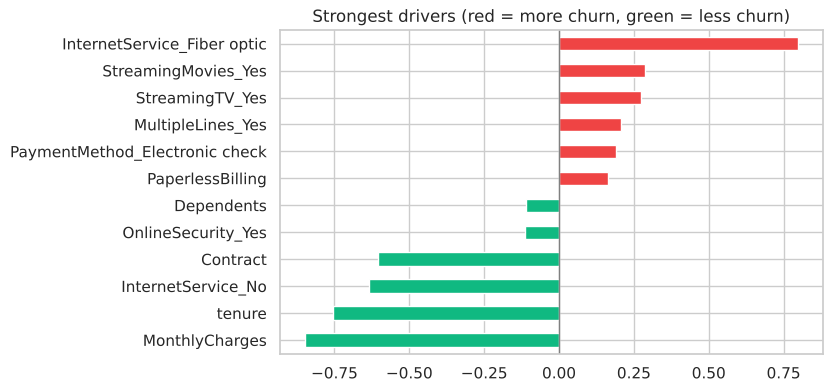

In [12]:
# balanced weights for the imbalance
model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

# top coefficients
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
top = pd.concat([coefs.head(6), coefs.tail(6)])
top.plot(kind="barh", color=["#10b981" if v < 0 else "#ef4444" for v in top], figsize=(7, 4.2))
plt.title("Strongest drivers (red = more churn, green = less churn)")
plt.axvline(0, color="gray", lw=1)
plt.show()

<div style="border-left:6px solid #dc2626;background:#fef2f2;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#dc2626">What I see</b><br><b>Fiber optic internet</b> is the biggest push toward leaving, then streaming add ons and paying by electronic check. On the other side, <b>tenure, longer contracts and not having internet</b> all push toward staying. One thing confused me at first: <b>MonthlyCharges</b> came out negative, even though higher bills went with more churn in the heatmap. After digging in, it's because MonthlyCharges overlaps a lot with fiber and streaming (r ≈ 0.79). Once the model already accounts for those, the leftover effect of price flips. Good lesson that you can't always read coefficients at face value when features are correlated.</div>

## 7–8. Test the Model and Measure It

Baseline accuracy (always 'No'): 0.735
Model accuracy:                  0.740

              precision    recall  f1-score   support

      Stayed       0.90      0.73      0.80      1035
     Churned       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



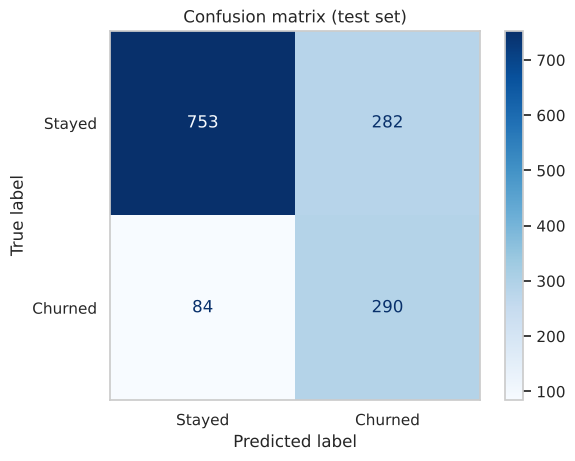

In [13]:
# predict on test set
y_pred = model.predict(X_test_s)

print(f"Baseline accuracy (always 'No'): {1 - y_test.mean():.3f}")
print(f"Model accuracy:                  {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

# confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.grid(False)
plt.show()

<div style="border-left:6px solid #2563eb;background:#eff6ff;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#2563eb">Reading the confusion matrix</b><br>Honestly, the accuracy (74%) barely beats the 73.5% "always No" baseline. But that baseline catches zero churners, and my model catches about <b>4 out of 5</b> (recall 0.78). The tradeoff is more false alarms, where loyal customers get flagged as risky. I think that's worth it. A false alarm just means someone gets a discount they didn't need, but a missed churner means the company loses that customer for good.</div>

## 9. Summary

<div style="background:#f8fafc;border:1px solid #cbd5e1;border-radius:10px;padding:14px 18px">

**What I learned about the data**
- **Contract type matters most.** Month to month customers leave way more often than people on one or two year contracts.
- **The first few months are the danger zone.** If a customer makes it past the start, they usually stick around for years.
- **Fiber customers and people who pay by electronic check leave more**, while having online security goes with staying.
- **Clustering without labels** found a "new, month to month, fiber" group that churns at 49%, compared to around 11% for the other two groups.

**How well the model worked**
- Logistic Regression catches about **78% of churners** on data it never saw, which is a lot more useful than the "always No" baseline that catches nobody.
- Precision for churners is only about 51%, so roughly half the people it flags would've stayed anyway. That's fine for something cheap like a check in email, but I wouldn't use it to hand out big discounts.
- **If I kept going,** I'd tune the decision threshold based on what each mistake actually costs, and try a tree model like Random Forest, since I think combos like "new AND month to month AND fiber" are where the real story is.

**My takeaway:** if I were this company, I'd focus on new month to month customers and try to get them onto longer contracts early. That's where most of the churn risk is hiding.
</div>